# Άσκηση 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar
import math

## Γραφική Παράσταση:

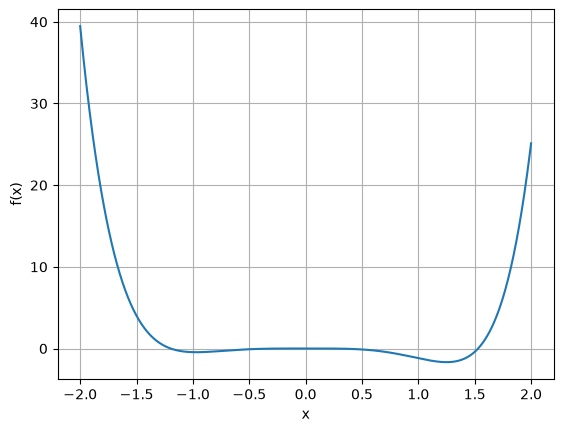

In [2]:
x=np.linspace(-2,2,1000)
y=np.exp(np.sin(x)**3) + x**6 - 2*x**4 - x**3 - 1
plt.plot(x,y)
plt.grid(True, axis='both')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.show()

In [3]:
def f(x):
    return np.expm1(np.sin(x)**3) + x**6 - 2*x**4 - x**3

def df(x):
    return (3 * np.exp(np.sin(x)**3) *
            np.sin(x)**2 * np.cos(x)
            + 6*x**5 - 8*x**3 - 3*x**2)

## Διχοτόμηση
Η μέθοδος της διχοτόμησης δεν μπορεί να εφαρμοστεί για τη ρίζα x = 0, επειδή η f(x) είναι αρνητική τόσο αριστερά όσο και δεξιά του 0. 

In [4]:
def bisection(f, a, b, tol, max_iter):

    if f(a)*f(b)>=0:
        return None, 0

    i=0

    while abs(b-a)/2.0>=tol and i<max_iter:
        c=(a+b)/2.0
        if f(c)==0:
            return c, i
        i+=1
        if f(a)*f(c)<0:
            b=c
        else:
            a=c
    return (a+b)/2.0, i



## Newton-Raphson

In [5]:
def newton_raphson(f, df, x0, tol, max_iter):

    x=x0
    i=0

    fx=f(x)
    dfx=df(x)

    if dfx==0:
        print('df=0')
        return x, i

    x_new=x-fx/dfx
    err=abs(x_new-x)
    x=x_new
    i+=1

    while err>=tol and i<max_iter:

        fx=f(x)
        dfx=df(x)

        if dfx==0:
            print('df=0')
            break

        x_new=x-fx/dfx
        err=abs(x_new-x)
        x=x_new
        i+=1
        
    return x, i


## Μέθοδος Τέμνουσας

In [6]:
def secant(f,x0, x1, tol, max_iter):

    i=0

    f0, f1=f(x0),f(x1)

    if f1-f0==0:
        return x1, i
    
    x2=x1-f1*(x1-x0)/(f1-f0)
    x0, x1 = x1, x2
    i+=1

    while abs(x1-x0)>=tol and i<max_iter:
        f0, f1=f(x0),f(x1)
        if f1-f0==0:
            break
        x2=x1-f1*(x1-x0)/(f1-f0)
        x0, x1 = x1, x2
        i+=1
    return x1, i

In [7]:

np.random.seed(42)

# r1 (≈ -1.1976235):
bis_r1, new_r1, sec_r1 = [], [], []

for i in range(10):
  # bisection
  a = np.random.uniform(-1.4, -1.20)
  b = np.random.uniform(-1.19, -1.0)
  _, iters_b = bisection(f, a, b, tol=1e-8, max_iter=200)
  bis_r1.append(iters_b)

  # newton-raphson
  x0 = np.random.uniform(-1.3, -1.0)
  _, iters_n = newton_raphson(f, df, x0, tol=1e-8, max_iter=200)
  new_r1.append(iters_n)

  # secant
  x0, x1 = np.random.uniform(-1.4, -1.0, size=2)
  _, iters_s = secant(f, x0, x1, tol=1e-8, max_iter=200)
  sec_r1.append(iters_s)

# r2 (= 0):
new_r2, sec_r2 = [], []

for i in range(10):
  # newton-raphson
  x0 = np.random.uniform(-0.05, 0.05)
  _, iters_n = newton_raphson(f, df, x0, tol=1e-10, max_iter=200)
  new_r2.append(iters_n)

  # secant
  x0, x1 = np.random.uniform(-0.05, 0.05, size=2)
  _, iters_s = secant(f, x0, x1, tol=1e-10, max_iter=200)
  sec_r2.append(iters_s)

# r3 (≈ 1.5301336):
bis_r3, new_r3, sec_r3 = [], [], []

for i in range(10):
  # bisection
  a = np.random.uniform(1.35, 1.50)
  b = np.random.uniform(1.55, 1.70)
  _, iters_b = bisection(f, a, b, tol=1e-8, max_iter=200)
  bis_r3.append(iters_b)

  # newton-raphson
  x0 = np.random.uniform(1.4, 1.6)
  _, iters_n = newton_raphson(f, df, x0, tol=1e-8, max_iter=200)
  new_r3.append(iters_n)

  # secant
  x0, x1 = np.random.uniform(1.4, 1.6, size=2)
  _, iters_s = secant(f, x0, x1, tol=1e-8, max_iter=200)
  sec_r3.append(iters_s)


def print_stats(title, lst):
  print(
      f"{title:<16} -> Min: {min(lst):2d} | Mean: {np.mean(lst):5.1f} | Max:"
      f" {max(lst):2d}"
  )


print("--- 1η Ρίζα ---")
print_stats("Διχοτόμηση", bis_r1)
print_stats("Newton-Raphson", new_r1)
print_stats("Τέμνουσα", sec_r1)

print("\n--- 2η Ρίζα ---")
print("Διχοτόμηση       -> Δεν εφαρμόζεται")
print_stats("Newton-Raphson", new_r2)
print_stats("Τέμνουσα", sec_r2)

print("\n--- 3η Ρίζα ---")
print_stats("Διχοτόμηση", bis_r3)
print_stats("Newton-Raphson", new_r3)
print_stats("Τέμνουσα", sec_r3)

--- 1η Ρίζα ---
Διχοτόμηση       -> Min: 23 | Mean:  23.6 | Max: 25
Newton-Raphson   -> Min:  4 | Mean:   5.5 | Max:  8
Τέμνουσα         -> Min:  5 | Mean:   7.0 | Max: 13

--- 2η Ρίζα ---
Διχοτόμηση       -> Δεν εφαρμόζεται
Newton-Raphson   -> Min: 58 | Mean:  64.3 | Max: 66
Τέμνουσα         -> Min: 87 | Mean:  90.0 | Max: 93

--- 3η Ρίζα ---
Διχοτόμηση       -> Min: 23 | Mean:  23.9 | Max: 24
Newton-Raphson   -> Min:  3 | Mean:   4.6 | Max:  5
Τέμνουσα         -> Min:  4 | Mean:   6.0 | Max:  7


In [8]:
def newton_raphson_history(f, df, x0, tol, max_iter):
  x = x0
  i = 0
  history = [x]

  fx = f(x)
  dfx = df(x)
  if dfx == 0:
    return x, i, history

  x_new = x - fx / dfx
  err = abs(x_new - x)
  x = x_new
  history.append(x)
  i += 1

  while err >= tol and i < max_iter:
    fx = f(x)
    dfx = df(x)
    if dfx == 0:
      break

    x_new = x - fx / dfx
    err = abs(x_new - x)
    x = x_new
    history.append(x)
    i += 1

  return x, i, history

In [9]:
r1_true, _ = newton_raphson(f, df, -1.2, 1e-15, 200)
r2_true = 0.0
r3_true, _ = newton_raphson(f, df, 1.5, 1e-15, 200)
print(r1_true, ', ', r2_true, ', ', r3_true)

-1.19762372213357 ,  0.0 ,  1.5301335081666156


In [10]:
# r1 (≈ -1.1976235):
x, i, history=newton_raphson_history(f, df, -1.1, tol=1e-8, max_iter=200)
errs = []
j = 0
while j < len(history):
    e = abs(history[j] - r1_true)
    if e > 1e-14:
        errs.append(e)
    j += 1


k = 1
while k < len(errs) - 1:
    p_k = np.log(errs[k + 1] / errs[k]) / np.log(errs[k] / errs[k - 1])
    print(f"k={k}: p_k = {p_k:.4f}")
    k += 1

k=1: p_k = 3.6093
k=2: p_k = 1.8935
k=3: p_k = 1.9873
k=4: p_k = 1.9997


In [11]:
# r2 (= 0):
x, i, history=newton_raphson_history(f, df, 0.5, tol=1e-8, max_iter=200)
errs = []
j = 0
while j < len(history):
    e = abs(history[j] - r1_true)
    if e > 1e-14:
        errs.append(e)
    j += 1


k = 1
while k < len(errs) - 1:
    p_k = np.log(errs[k + 1] / errs[k]) / np.log(errs[k] / errs[k - 1])
    print(f"k={k}: p_k = {p_k:.4f}")
    k += 1

k=1: p_k = 0.7619
k=2: p_k = 0.7729
k=3: p_k = 0.7740
k=4: p_k = 0.7717
k=5: p_k = 0.7684
k=6: p_k = 0.7650
k=7: p_k = 0.7620
k=8: p_k = 0.7594
k=9: p_k = 0.7573
k=10: p_k = 0.7556
k=11: p_k = 0.7543
k=12: p_k = 0.7532
k=13: p_k = 0.7525
k=14: p_k = 0.7519
k=15: p_k = 0.7514
k=16: p_k = 0.7511
k=17: p_k = 0.7508
k=18: p_k = 0.7506
k=19: p_k = 0.7504
k=20: p_k = 0.7503
k=21: p_k = 0.7503
k=22: p_k = 0.7502
k=23: p_k = 0.7501
k=24: p_k = 0.7501
k=25: p_k = 0.7501
k=26: p_k = 0.7501
k=27: p_k = 0.7500
k=28: p_k = 0.7500
k=29: p_k = 0.7500
k=30: p_k = 0.7500
k=31: p_k = 0.7500
k=32: p_k = 0.7500
k=33: p_k = 0.7500
k=34: p_k = 0.7500
k=35: p_k = 0.7500
k=36: p_k = 0.7500
k=37: p_k = 0.7500
k=38: p_k = 0.7500
k=39: p_k = 0.7500
k=40: p_k = 0.7500
k=41: p_k = 0.7500
k=42: p_k = 0.7500
k=43: p_k = 0.7500
k=44: p_k = 0.7500
k=45: p_k = 0.7500
k=46: p_k = 0.7500
k=47: p_k = 0.7500
k=48: p_k = 0.7500
k=49: p_k = 0.7500
k=50: p_k = 0.7500
k=51: p_k = 0.7500
k=52: p_k = 0.7500
k=53: p_k = 0.7500
k=

In [12]:
# r3 (≈ 1.5301336):
x, i, history=newton_raphson_history(f, df, -1.1, tol=1e-8, max_iter=200)
errs = []
j = 0
while j < len(history):
    e = abs(history[j] - r1_true)
    if e > 1e-14:
        errs.append(e)
    j += 1


k = 1
while k < len(errs) - 1:
    p_k = np.log(errs[k + 1] / errs[k]) / np.log(errs[k] / errs[k - 1])
    print(f"k={k}: p_k = {p_k:.4f}")
    k += 1

k=1: p_k = 3.6093
k=2: p_k = 1.8935
k=3: p_k = 1.9873
k=4: p_k = 1.9997


Η μέθοδος Newton-Raphson δεν συγκλίνει τετραγωνικά για ρίζες στις οποίες μηδενίζεται ταυτόχρονα και η πρώτη παράγωγος της συνάρτησης.
Στη συγκεκριμένη άσκηση είναι η r=0.

In [13]:
print(f"f(-1.1976235): {f(-1.1976235):.16f}")
print(f"df(-1.1976235): {df(-1.1976235):.16f}")

f(-1.1976235): -0.0000010930244252
df(-1.1976235): -4.9205689443230503


In [14]:
print('f(0): ', f(0))
print('df(0): ', df(0))

f(0):  0.0
df(0):  0.0


In [15]:
print(f"f(1.5301336): {f(1.5301336):.16f}")
print(f"df(1.5301336): {df(1.5301336):.16f}")

f(1.5301336): 0.0000013749969621
df(1.5301336): 14.9727395197571376


# 'Ασκηση 2

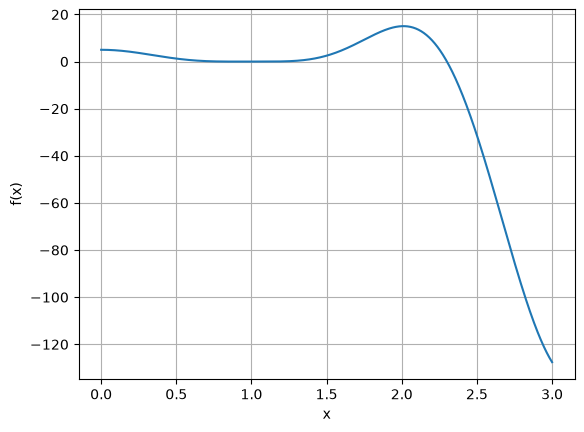

In [16]:

x=np.linspace(0,3,1000)
y = (
    94 * np.cos(x) ** 3
    - 24 * np.cos(x)
    + 177 * np.sin(x) ** 2
    - 108 * np.sin(x) ** 4
    - 72 * (np.cos(x) ** 3) * (np.sin(x) ** 2)
    - 65
)
plt.plot(x,y)
plt.grid(True, axis='both')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.show()

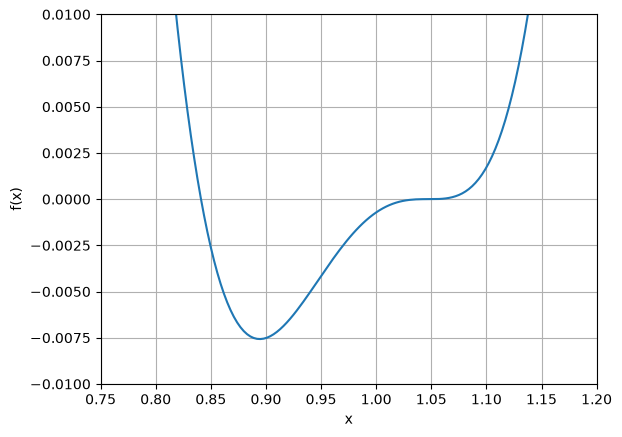

In [17]:

x=np.linspace(0,3,1000)
y = (
    94 * np.cos(x) ** 3
    - 24 * np.cos(x)
    + 177 * np.sin(x) ** 2
    - 108 * np.sin(x) ** 4
    - 72 * (np.cos(x) ** 3) * (np.sin(x) ** 2)
    - 65
)
plt.plot(x,y)
plt.xlim(0.75, 1.20)
plt.ylim(-0.01, 0.01)
plt.grid(True, axis='both')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.show()

In [18]:
def f(x):
  return (
      94 * np.cos(x) ** 3
      - 24 * np.cos(x)
      + 177 * np.sin(x) ** 2
      - 108 * np.sin(x) ** 4
      - 72 * (np.cos(x) ** 3) * (np.sin(x) ** 2)
      - 65
  )

def df(x):
  s = np.sin(x)
  c = np.cos(x)
  return (
      -282 * (c**2) * s
      + 24 * s
      + 354 * s * c
      - 432 * (s**3) * c
      + 216 * (c**2) * (s**3)
      - 144 * (c**4) * s
  )

def d2f(x):
  s = np.sin(x)
  c = np.cos(x)
  return (
      564 * c * (s**2)
      - 282 * (c**3)
      + 24 * c
      + 354 * (c**2)
      - 354 * (s**2)
      - 1296 * (s**2) * (c**2)
      + 432 * (s**4)
      - 432 * c * (s**4)
      + 1224 * (c**3) * (s**2)
      - 144 * (c**5)
  )

## Τροποποιημένη Newton-Raphson

In [19]:
def newton_raphson_modified(f, df, d2f, x0, tol, max_iter):

    x=x0
    i=0

    fx=f(x)
    dfx=df(x)
    d2fx = d2f(x)

    if dfx==0:
        print('df=0')
        return x, i

    x_new=x-fx/dfx
    err=abs(x_new-x)
    x=x_new
    i+=1

    while err>=tol and i<max_iter:

        fx=f(x)
        dfx=df(x)
        d2fx = d2f(x)

        if dfx==0:
            print('df=0')
            break

        x_new = x - (fx / dfx) - 0.5 * ((fx**2) * d2fx) / (dfx**3)
        err=abs(x_new-x)
        x=x_new
        i+=1
        
    return x, i


## Τροποποιημένη Μέθοδος Διχοτόμησης

In [34]:
def bisection_modified(f, a, b, tol, max_iter):
    if f(a) * f(b) >= 0:
        return None, 0

    i = 0

    while 2 * abs(b - a) / 3.0 >= tol and i < max_iter:
        if abs(f(a)) < abs(f(b)):
            c = a + (b - a) / 3.0
        else:
            c = b - (b - a) / 3.0

        i += 1

        #if f(c) == 0:
            #return c, i

        if f(a) * f(c) < 0:
            b = c
        else:
            a = c

    if abs(f(a)) < abs(f(b)):
        c = a + (b - a) / 3.0
    else:
        c = b - (b - a) / 3.0

    return c, i
   

## Τροποποιημένη Μέθοδος Τέμνουσας

In [35]:
def secant_modified(f, x0, x1, x2, tol, max_iter):
    i = 0

    while i < max_iter:
        f0, f1, f2 = f(x0), f(x1), f(x2)

        if f2 == 0:
            return x2, i
        if f1 == 0:
            return x1, i
        if f0 == 0:
            return x0, i

        q = f0 / f1
        r = f2 / f1
        s = f2 / f0

        denom = (q - 1.0) * (r - 1.0) * (s - 1.0)
        if denom == 0:
            break

        numer = r * (r - q) * (x2 - x1) + (1.0 - r) * s * (x2 - x0)
        x3 = x2 - numer / denom

        i += 1

        if abs(x3 - x2) < tol:
            return x3, i

        x0, x1, x2 = x1, x2, x3

    return x2, i

In [36]:


print("--- 1η Ρίζα ---")
print("Διχοτόμηση", bisection_modified(f, 0.83, 0.85, 1e-9, 500))
print("Newton-Raphson", newton_raphson_modified(f, df, d2f, 0.84, 1e-9, 500))
print("Τέμνουσα", secant_modified(f, 0.8, 0.85, 0.86, 1e-9, 500))

print("--- 2η Ρίζα ---")
print("Διχοτόμηση", bisection_modified(f, 1.04, 1.06, 1e-9, 500))
print("Newton-Raphson", newton_raphson_modified(f, df, d2f, 1.04, 1e-9, 500))
print("Τέμνουσα", secant_modified(f, 1.04, 1.045, 1.055, 1e-9, 500))

print("--- 3η Ρίζα ---")
print("Διχοτόμηση", bisection_modified(f, 2.2, 2.4, 1e-9, 500))
print("Newton-Raphson", newton_raphson_modified(f, df, d2f, 2.3, 1e-9, 500))
print("Τέμνουσα", secant_modified(f, 2.2, 2.3, 2.4, 1e-9, 500))

--- 1η Ρίζα ---
Διχοτόμηση (0.8410686708558555, 19)
Newton-Raphson (np.float64(0.8410686705678923), 3)
Τέμνουσα (np.float64(0.8410686705679266), 5)
--- 2η Ρίζα ---
Διχοτόμηση (1.0472702322794432, 27)
Newton-Raphson (np.float64(1.047207222823591), 46)
Τέμνουσα (np.float64(1.0471848882970658), 17)
--- 3η Ρίζα ---
Διχοτόμηση (2.3005239826540236, 21)
Newton-Raphson (np.float64(2.300523983021863), 3)
Τέμνουσα (np.float64(2.300523983021863), 4)


In [39]:
import numpy as np

roots_ranges = {
    "1η Ρίζα (~0.841)": ((0.70, 0.83), (0.85, 0.95)),
    "2η Ρίζα (~1.047)": ((0.96, 1.04), (1.05, 1.15)),
    "3η Ρίζα (~2.301)": ((2.15, 2.29), (2.31, 2.45)),
}

for name, (range_a, range_b) in roots_ranges.items():
    iters = []
    for _ in range(20):
        a = np.random.uniform(*range_a)
        b = np.random.uniform(*range_b)
        _, it = bisection_modified(f, a, b, 1e-9, 500)
        iters.append(it)
    print(f"{name}: επαναλήψεις = {iters}")
    print(f"   Min: {min(iters)}, Max: {max(iters)}\n")

1η Ρίζα (~0.841): επαναλήψεις = [19, 21, 20, 18, 24, 21, 22, 22, 22, 22, 21, 20, 23, 20, 20, 22, 21, 21, 20, 19]
   Min: 18, Max: 24

2η Ρίζα (~1.047): επαναλήψεις = [25, 28, 22, 19, 21, 24, 24, 24, 34, 21, 41, 30, 28, 31, 24, 40, 33, 27, 25, 25]
   Min: 19, Max: 41

3η Ρίζα (~2.301): επαναλήψεις = [20, 21, 21, 21, 21, 21, 19, 19, 21, 23, 22, 22, 20, 24, 21, 21, 21, 20, 19, 20]
   Min: 19, Max: 24



Δεν συκγλίνει στον ίδιο αριθμό επαναλήψεων.
Στην 1η ρίζα οι επαναλήψεις κυμαίνονται από 18 έως 24, στη 2η από 19 έως 41, και στη 3η από 19 έως 24.

In [47]:
def bisection_history(f, a, b, tol, max_iter):
    if f(a) * f(b) >= 0:
        return None, 0, []
    i = 0
    history = []
    while abs(b - a) / 2.0 >= tol and i < max_iter:
        c = (a + b) / 2.0
        history.append(c)
        i += 1
        if f(c) == 0:
            return c, i, history
        if f(a) * f(c) < 0:
            b = c
        else:
            a = c
    c = (a + b) / 2.0
    history.append(c)
    return c, i, history

In [48]:
def secant_history(f, x0, x1, tol, max_iter):
    i = 0
    history = [x0, x1]
    while i < max_iter:
        f0 = f(x0)
        f1 = f(x1)
        if f1 - f0 == 0:
            break
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        history.append(x2)
        i += 1
        if abs(x2 - x1) < tol:
            return x2, i, history
        x0 = x1
        x1 = x2
    return x1, i, history

In [49]:
def bisection_modified_history(f, a, b, tol, max_iter):
    if f(a) * f(b) >= 0:
        return None, 0, []
    i = 0
    history = []
    while 2 * abs(b - a) / 3.0 >= tol and i < max_iter:
        if abs(f(a)) < abs(f(b)):
            c = a + (b - a) / 3.0
        else:
            c = b - (b - a) / 3.0
        history.append(c)
        i += 1
        if f(c) == 0:
            return c, i, history
        if f(a) * f(c) < 0:
            b = c
        else:
            a = c
    if abs(f(a)) < abs(f(b)):
        c = a + (b - a) / 3.0
    else:
        c = b - (b - a) / 3.0
    history.append(c)
    return c, i, history

In [50]:
def newton_raphson_modified_history(f, df, d2f, x0, tol, max_iter):
    x = x0
    i = 0
    history = [x]

    fx = f(x)
    dfx = df(x)
    if dfx == 0:
        return x, i, history

    x_new = x - fx / dfx
    err = abs(x_new - x)
    x = x_new
    history.append(x)
    i += 1

    while err >= tol and i < max_iter:
        fx = f(x)
        dfx = df(x)
        d2fx = d2f(x)
        if dfx == 0:
            break
        x_new = x - (fx / dfx) - 0.5 * ((fx**2) * d2fx) / (dfx**3)
        err = abs(x_new - x)
        x = x_new
        history.append(x)
        i += 1

    return x, i, history

In [51]:
def secant_modified_history(f, x0, x1, x2, tol, max_iter):
    i = 0
    history = [x0, x1, x2]
    while i < max_iter:
        f0 = f(x0)
        f1 = f(x1)
        f2 = f(x2)
        if f2 == 0:
            return x2, i, history
        if f1 == 0:
            return x1, i, history
        if f0 == 0:
            return x0, i, history

        q = f0 / f1
        r = f2 / f1
        s = f2 / f0

        denom = (q - 1.0) * (r - 1.0) * (s - 1.0)
        if denom == 0:
            break

        numer = r * (r - q) * (x2 - x1) + (1.0 - r) * s * (x2 - x0)
        x3 = x2 - numer / denom
        history.append(x3)
        i += 1

        if abs(x3 - x2) < tol:
            return x3, i, history

        x0 = x1
        x1 = x2
        x2 = x3
    return x2, i, history

In [52]:
r1_true, _, _ = newton_raphson_modified_history(f, df, d2f, 0.85, 1e-15, 500)
r2_true = np.pi / 3.0
r3_true, _, _ = newton_raphson_modified_history(f, df, d2f, 2.30, 1e-15, 500)

print(r1_true, ',', r2_true, ',', r3_true)

0.8410686705679031 , 1.0471975511965976 , 2.300523983021863


In [56]:
def get_final_pk(history, r_true, skip=0):
    errs = []
    j = skip
    while j < len(history):
        e = abs(history[j] - r_true)
        if e > 1e-11:
            errs.append(e)
        j += 1

    if len(errs) < 3:
        return None

    k = len(errs) - 2
    p_k = np.log(errs[k + 1] / errs[k]) / np.log(errs[k] / errs[k - 1])
    return p_k


roots_config = [
    ("1η Ρίζα (~0.841)", r1_true, (0.75, 0.83), (0.85, 0.90)),
    ("2η Ρίζα (~1.047)", r2_true, (0.95, 1.04), (1.05, 1.15)),
    ("3η Ρίζα (~2.301)", r3_true, (2.15, 2.29), (2.31, 2.45)),
]

for title, r_true, (a_min, a_max), (b_min, b_max) in roots_config:
    iters_bis_cl, iters_bis_md = [], []
    iters_nr_cl, iters_nr_md = [], []
    iters_sc_cl, iters_sc_md = [], []

    pk_nr_cl, pk_nr_md = [], []
    pk_sc_cl, pk_sc_md = [], []

    run = 0
    while run < 100:
        a = np.random.uniform(a_min, a_max)
        b = np.random.uniform(b_min, b_max)
        pts = sorted(np.random.uniform(a_min, b_max, 3))

        _, it1, _ = bisection_history(f, a, b, 1e-9, 500)
        _, it2, _ = bisection_modified_history(f, a, b, 1e-9, 500)

        _, it3, h3 = newton_raphson_history(f, df, pts[0], 1e-9, 500)
        _, it4, h4 = newton_raphson_modified_history(f, df, d2f, pts[0], 1e-9, 500)

        _, it5, h5 = secant_history(f, pts[0], pts[1], 1e-9, 500)
        _, it6, h6 = secant_modified_history(f, pts[0], pts[1], pts[2], 1e-9, 500)

        iters_bis_cl.append(it1)
        iters_bis_md.append(it2)
        iters_nr_cl.append(it3)
        iters_nr_md.append(it4)
        iters_sc_cl.append(it5)
        iters_sc_md.append(it6)

        p3 = get_final_pk(h3, r_true, skip=0)
        p4 = get_final_pk(h4, r_true, skip=0)
        p5 = get_final_pk(h5, r_true, skip=1)
        p6 = get_final_pk(h6, r_true, skip=2)

        if p3 is not None: pk_nr_cl.append(p3)
        if p4 is not None: pk_nr_md.append(p4)
        if p5 is not None: pk_sc_cl.append(p5)
        if p6 is not None: pk_sc_md.append(p6)

        run += 1

    print(f"=== ΣΥΓΚΡΙΣΗ 100 ΕΚΤΕΛΕΣΕΩΝ ({title}) ===")
    print(f"Διχοτόμηση Κλασική      -> Μέσες επαναλήψεις: {np.mean(iters_bis_cl):.2f}")
    print(f"Διχοτόμηση Τροποποιημένη -> Μέσες επαναλήψεις: {np.mean(iters_bis_md):.2f}")
    print(f"Newton Κλασική          -> Μέσες επαναλήψεις: {np.mean(iters_nr_cl):.2f} | Μέσο p_k: {np.mean(pk_nr_cl):.2f}")
    print(f"Newton Τροποποιημένη    -> Μέσες επαναλήψεις: {np.mean(iters_nr_md):.2f} | Μέσο p_k: {np.mean(pk_nr_md):.2f}")
    print(f"Τέμνουσα Κλασική        -> Μέσες επαναλήψεις: {np.mean(iters_sc_cl):.2f} | Μέσο p_k: {np.mean(pk_sc_cl):.2f}")
    print(f"Τέμνουσα Τροποποιημένη  -> Μέσες επαναλήψεις: {np.mean(iters_sc_md):.2f} | Μέσο p_k: {np.mean(pk_sc_md):.2f}\n")

=== ΣΥΓΚΡΙΣΗ 100 ΕΚΤΕΛΕΣΕΩΝ (1η Ρίζα (~0.841)) ===
Διχοτόμηση Κλασική      -> Μέσες επαναλήψεις: 25.77
Διχοτόμηση Τροποποιημένη -> Μέσες επαναλήψεις: 20.27
Newton Κλασική          -> Μέσες επαναλήψεις: 6.14 | Μέσο p_k: 1.99
Newton Τροποποιημένη    -> Μέσες επαναλήψεις: 4.80 | Μέσο p_k: 2.84
Τέμνουσα Κλασική        -> Μέσες επαναλήψεις: 7.34 | Μέσο p_k: 1.62
Τέμνουσα Τροποποιημένη  -> Μέσες επαναλήψεις: 7.59 | Μέσο p_k: 1.90

=== ΣΥΓΚΡΙΣΗ 100 ΕΚΤΕΛΕΣΕΩΝ (2η Ρίζα (~1.047)) ===
Διχοτόμηση Κλασική      -> Μέσες επαναλήψεις: 13.63
Διχοτόμηση Τροποποιημένη -> Μέσες επαναλήψεις: 10.74
Newton Κλασική          -> Μέσες επαναλήψεις: 24.79 | Μέσο p_k: 0.00
Newton Τροποποιημένη    -> Μέσες επαναλήψεις: 21.43 | Μέσο p_k: 0.00
Τέμνουσα Κλασική        -> Μέσες επαναλήψεις: 27.96 | Μέσο p_k: -0.06
Τέμνουσα Τροποποιημένη  -> Μέσες επαναλήψεις: 23.28 | Μέσο p_k: -1.62

=== ΣΥΓΚΡΙΣΗ 100 ΕΚΤΕΛΕΣΕΩΝ (3η Ρίζα (~2.301)) ===
Διχοτόμηση Κλασική      -> Μέσες επαναλήψεις: 26.66
Διχοτόμηση Τροποποιημένη -> Μέσες